<a href="https://colab.research.google.com/github/gaaj-ufrpe/pisi_adam/blob/main/pisi_adam_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar o dataset Iris
iris = load_iris()
X = iris.data
y = iris.target

# Criar um DataFrame para facilitar a EDA e visualização
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = y
df['species_name'] = df['species'].map(lambda x: iris.target_names[x])

print("=== Agrupamento com K-Means ===")
# K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10) # Iris tem 3 classes naturais
kmeans_labels = kmeans.fit_predict(X)
print("Rótulos dos clusters K-Means:\n", kmeans_labels)

print("\n=== Agrupamento com DBSCAN ===")
# DBSCAN requer escalonamento dos dados para melhor desempenho
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Ajustar os parâmetros eps e min_samples conforme necessário para o dataset
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)
print("Rótulos dos clusters DBSCAN:\n", dbscan_labels)

# Para uma análise mais detalhada, você pode comparar os rótulos
# com as classes verdadeiras (y) ou usar métricas de avaliação.
# Exemplo: Mostrar a contagem de rótulos para DBSCAN (rótulo -1 indica ruído)
unique_dbscan_labels, counts_dbscan_labels = pd.Series(dbscan_labels).value_counts().sort_index().index.tolist(), pd.Series(dbscan_labels).value_counts().sort_index().values.tolist()
print("\nContagem de rótulos DBSCAN:")
for label, count in zip(unique_dbscan_labels, counts_dbscan_labels):
    print(f"Cluster {label}: {count} amostras")


=== Agrupamento com K-Means ===
Rótulos dos clusters K-Means:
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

=== Agrupamento com DBSCAN ===
Rótulos dos clusters DBSCAN:
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1 -1 -1  1 -1 -1  1 -1  1  1  1  1  1 -1  1  1  1
 -1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1 -1  1  1  1  1  1 -1  1  1
  1  1 -1  1 -1  1  1  1  1 -1 -1 -1 -1 -1  1  1  1  1 -1  1  1 -1 -1 -1
  1  1 -1  1  1 -1  1  1  1 -1 -1 -1  1  1  1 -1 -1  1  1  1  1  1  1  1
  1  1  1  1 -1  1]

Contagem de rótulos DBSCAN:
Cluster -1: 34 amostras
Cluster 0: 45 amostras
Cluster 1: 71 amostras


### Análise Exploratória de Dados (EDA)

In [4]:
print("Primeiras 5 linhas do DataFrame:")
print(df.head())


Primeiras 5 linhas do DataFrame:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species species_name  
0        0       setosa  
1        0       setosa  
2        0       setosa  
3        0       setosa  
4        0       setosa  


In [5]:
print("Informações do DataFrame:")
df.info()


Informações do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [6]:
print("Estatísticas descritivas do DataFrame:")
print(df.describe())


Estatísticas descritivas do DataFrame:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)     species  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  


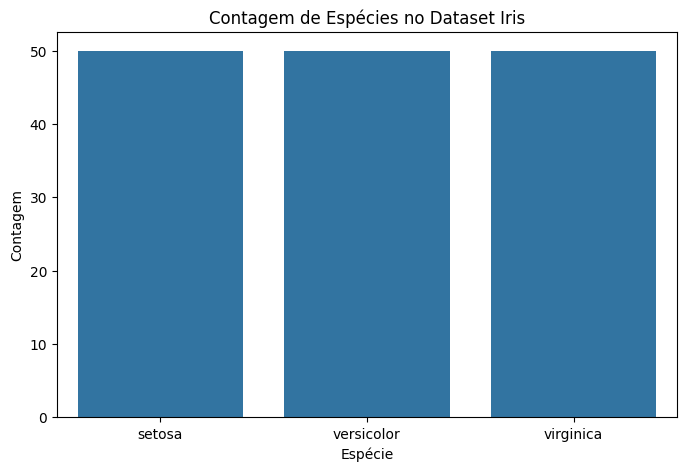

In [7]:
# Distribuição das espécies (variável alvo)
plt.figure(figsize=(8, 5))
sns.countplot(x='species_name', data=df)
plt.title('Contagem de Espécies no Dataset Iris')
plt.xlabel('Espécie')
plt.ylabel('Contagem')
plt.show()


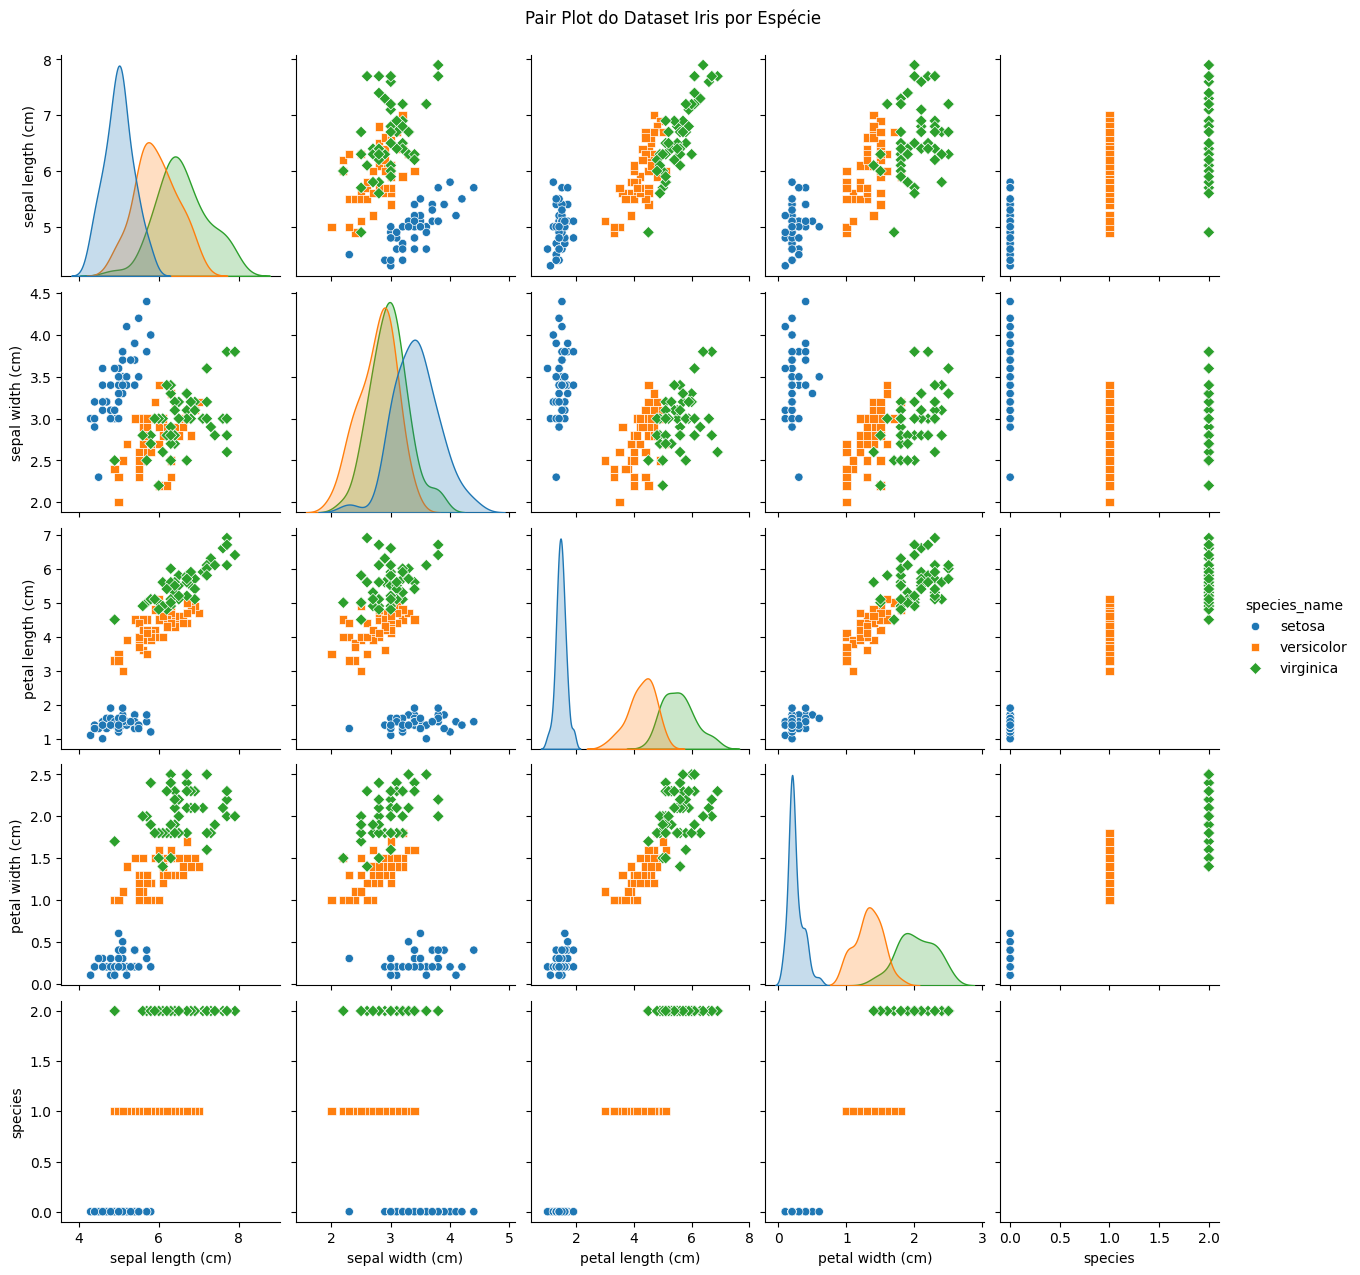

In [8]:
# Pair plot para visualizar a relação entre as características
# e como elas se separam pelas espécies verdadeiras
sns.pairplot(df, hue='species_name', markers=['o', 's', 'D'])
plt.suptitle('Pair Plot do Dataset Iris por Espécie', y=1.02)
plt.show()


### Visualização dos Agrupamentos

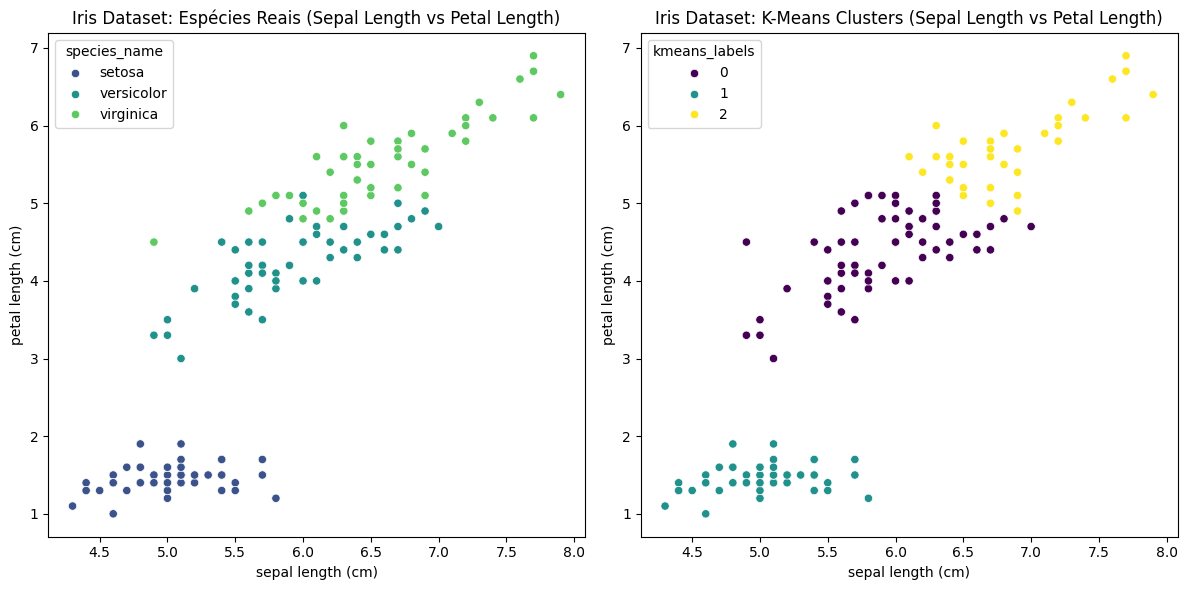

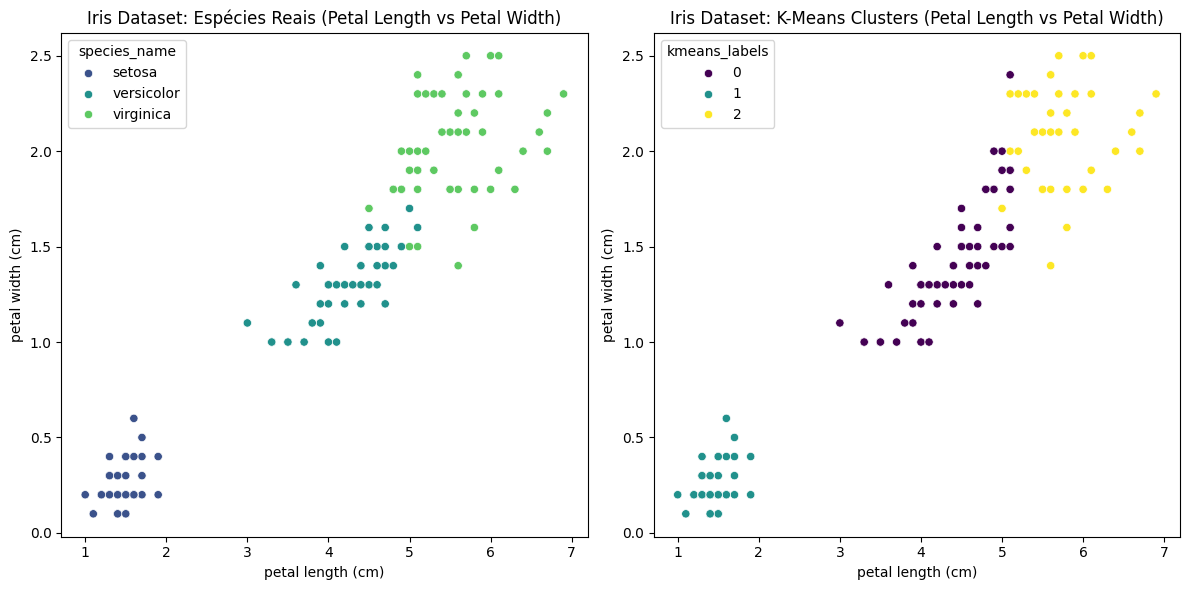

In [9]:
df['kmeans_labels'] = kmeans_labels

# Redução de dimensionalidade para visualização (sepal length vs petal length)
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x='sepal length (cm)', y='petal length (cm)', hue='species_name', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: Espécies Reais (Sepal Length vs Petal Length)')

plt.subplot(1, 2, 2)
sns.scatterplot(x='sepal length (cm)', y='petal length (cm)', hue='kmeans_labels', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: K-Means Clusters (Sepal Length vs Petal Length)')

plt.tight_layout()
plt.show()

# Outra combinação de características para visualizar K-Means
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x='petal length (cm)', y='petal width (cm)', hue='species_name', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: Espécies Reais (Petal Length vs Petal Width)')

plt.subplot(1, 2, 2)
sns.scatterplot(x='petal length (cm)', y='petal width (cm)', hue='kmeans_labels', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: K-Means Clusters (Petal Length vs Petal Width)')

plt.tight_layout()
plt.show()


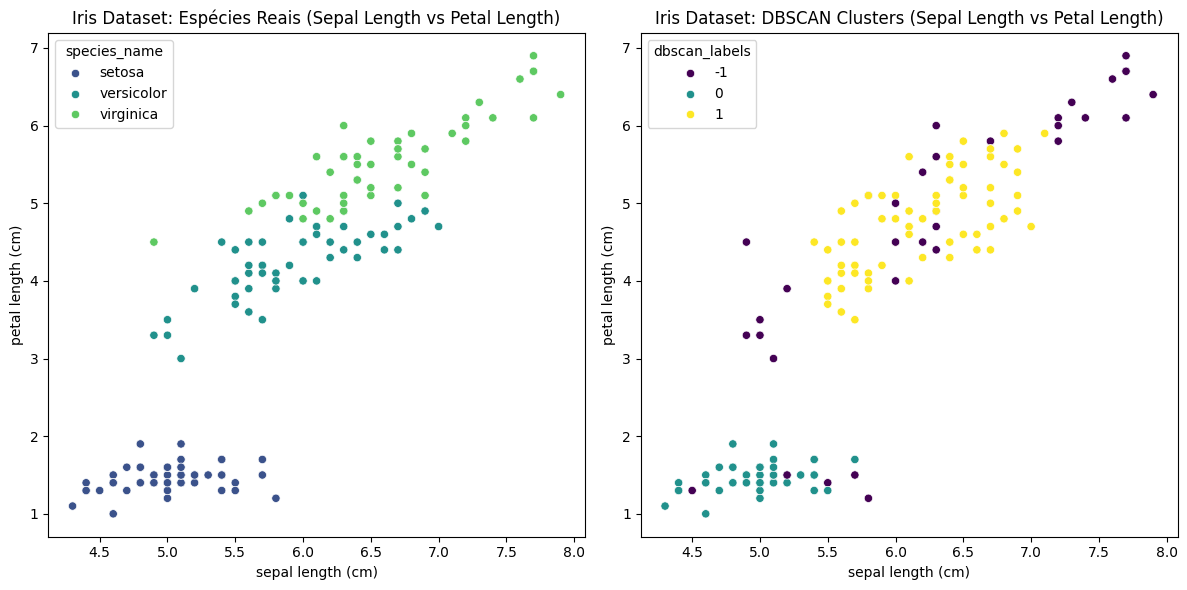

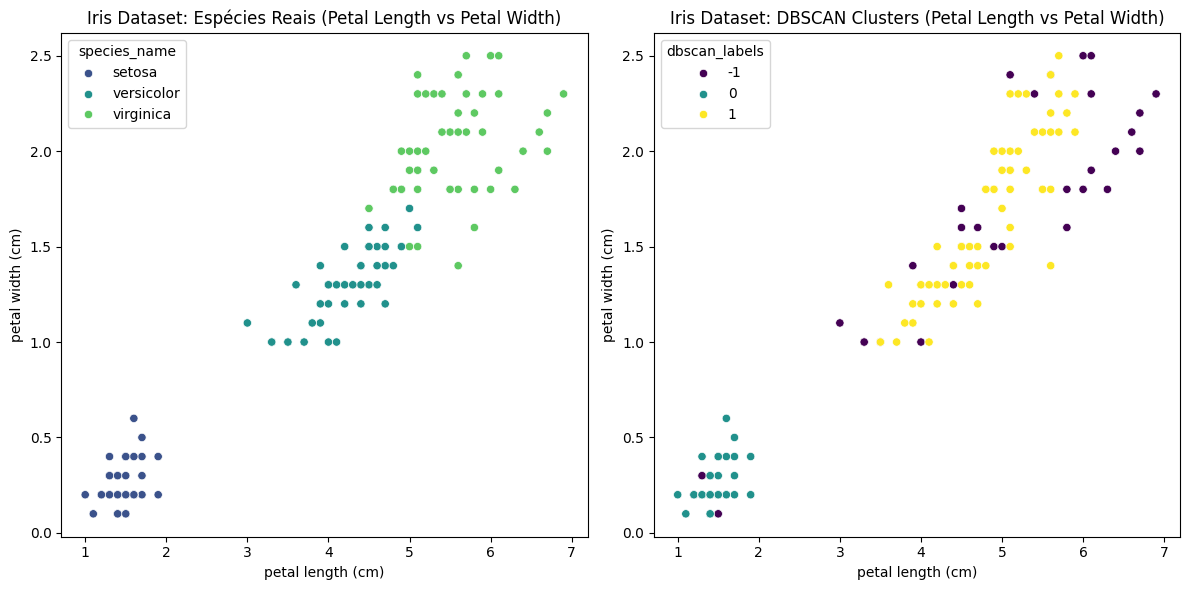

In [10]:
df['dbscan_labels'] = dbscan_labels

# Visualização dos clusters DBSCAN (Sepal Length vs Petal Length)
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x='sepal length (cm)', y='petal length (cm)', hue='species_name', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: Espécies Reais (Sepal Length vs Petal Length)')

plt.subplot(1, 2, 2)
sns.scatterplot(x='sepal length (cm)', y='petal length (cm)', hue='dbscan_labels', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: DBSCAN Clusters (Sepal Length vs Petal Length)')

plt.tight_layout()
plt.show()

# Outra combinação de características para visualizar DBSCAN
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x='petal length (cm)', y='petal width (cm)', hue='species_name', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: Espécies Reais (Petal Length vs Petal Width)')

plt.subplot(1, 2, 2)
sns.scatterplot(x='petal length (cm)', y='petal width (cm)', hue='dbscan_labels', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: DBSCAN Clusters (Petal Length vs Petal Width)')

plt.tight_layout()
plt.show()


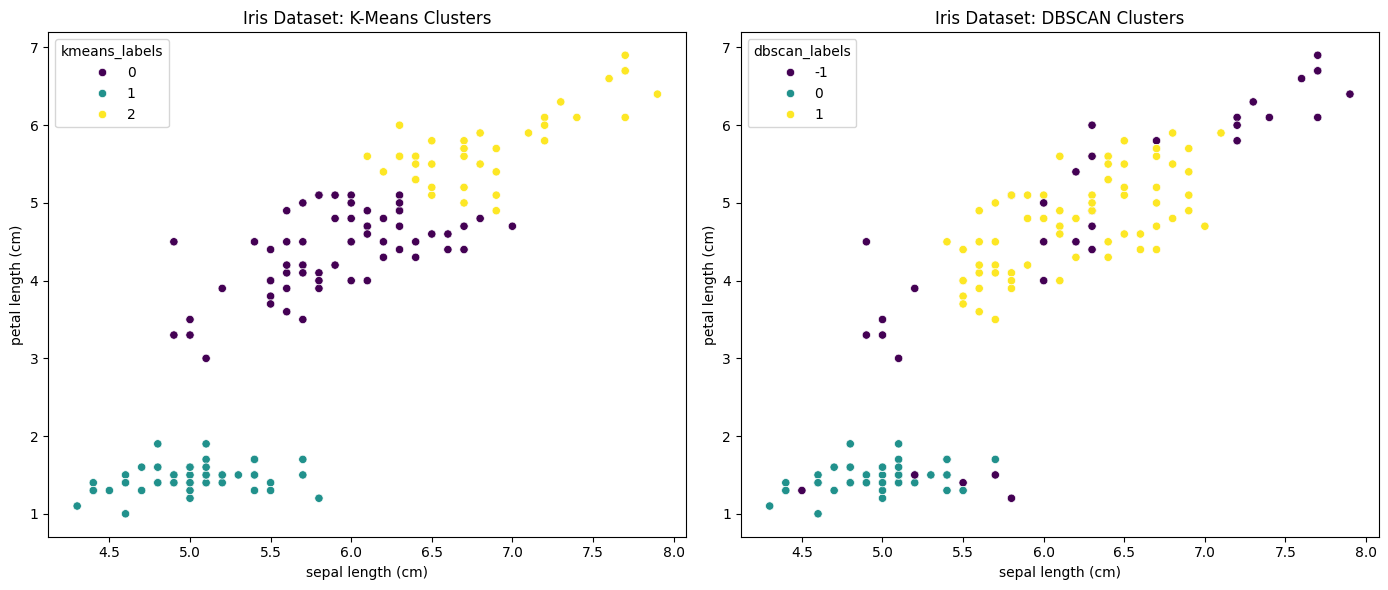

In [11]:
plt.figure(figsize=(14, 6))

# Subplot para K-Means
plt.subplot(1, 2, 1)
sns.scatterplot(x='sepal length (cm)', y='petal length (cm)', hue='kmeans_labels', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: K-Means Clusters')
plt.xlabel('sepal length (cm)')
plt.ylabel('petal length (cm)')

# Subplot para DBSCAN
plt.subplot(1, 2, 2)
sns.scatterplot(x='sepal length (cm)', y='petal length (cm)', hue='dbscan_labels', data=df, palette='viridis', legend='full')
plt.title('Iris Dataset: DBSCAN Clusters')
plt.xlabel('sepal length (cm)')
plt.ylabel('petal length (cm)')

plt.tight_layout()
plt.show()


=== Gráficos de Caixa por Cluster (K-Means vs DBSCAN) ===


/tmp/ipykernel_1807/3403794368.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='kmeans_labels', y=feature, data=df, palette='viridis')
/tmp/ipykernel_1807/3403794368.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='dbscan_labels', y=feature, data=df, palette='viridis')


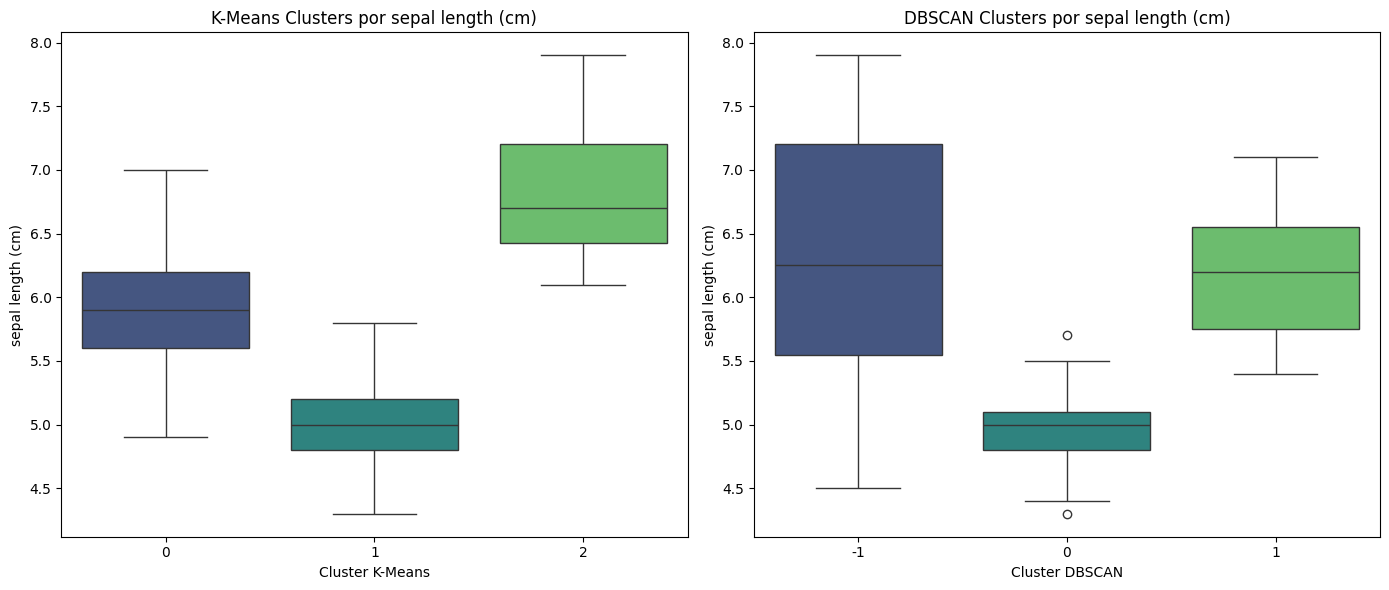

/tmp/ipykernel_1807/3403794368.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='kmeans_labels', y=feature, data=df, palette='viridis')
/tmp/ipykernel_1807/3403794368.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='dbscan_labels', y=feature, data=df, palette='viridis')


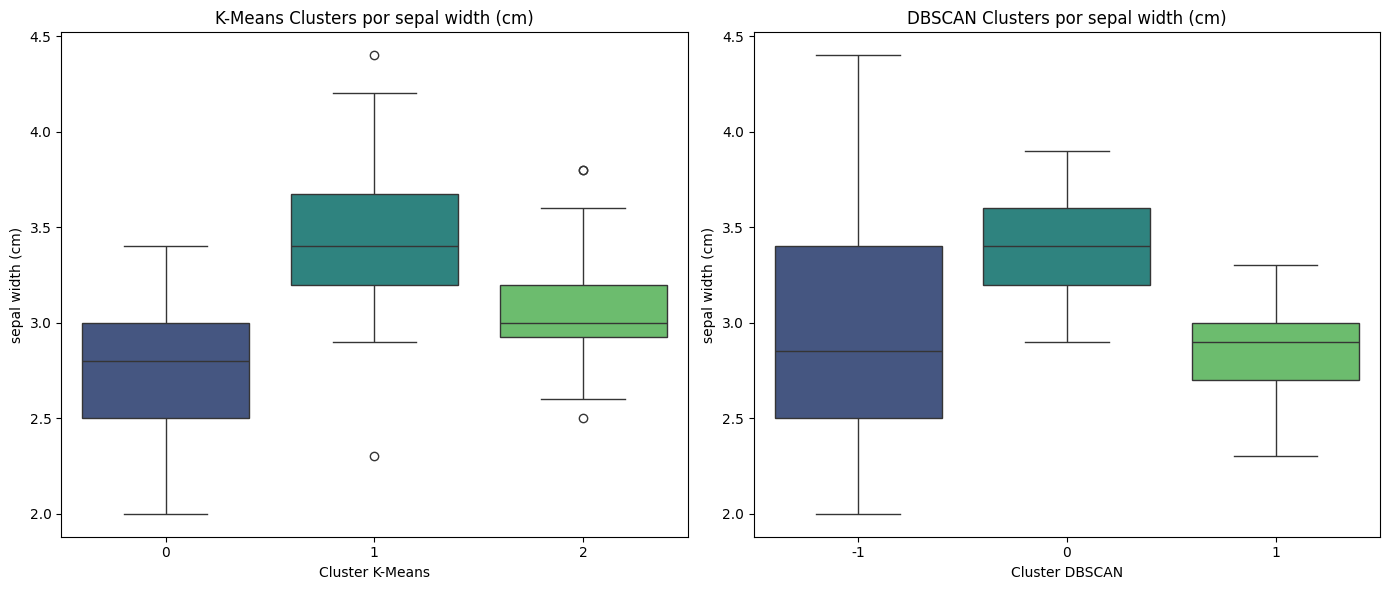

/tmp/ipykernel_1807/3403794368.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='kmeans_labels', y=feature, data=df, palette='viridis')
/tmp/ipykernel_1807/3403794368.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='dbscan_labels', y=feature, data=df, palette='viridis')


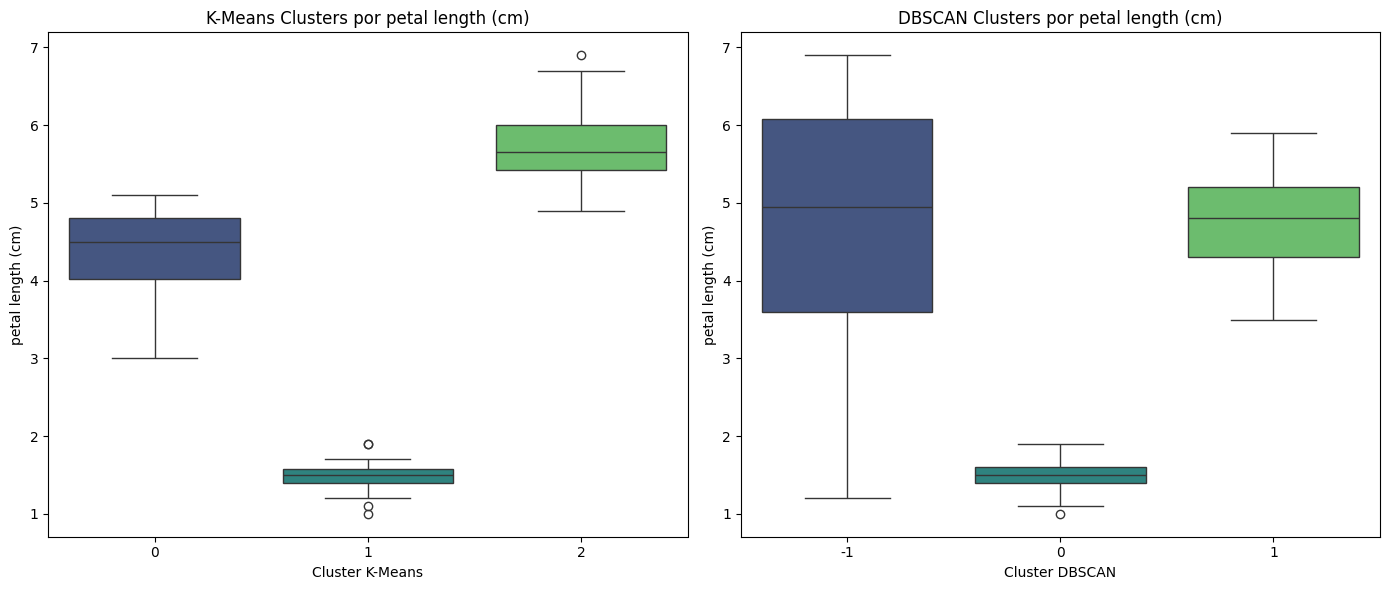

/tmp/ipykernel_1807/3403794368.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='kmeans_labels', y=feature, data=df, palette='viridis')
/tmp/ipykernel_1807/3403794368.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='dbscan_labels', y=feature, data=df, palette='viridis')


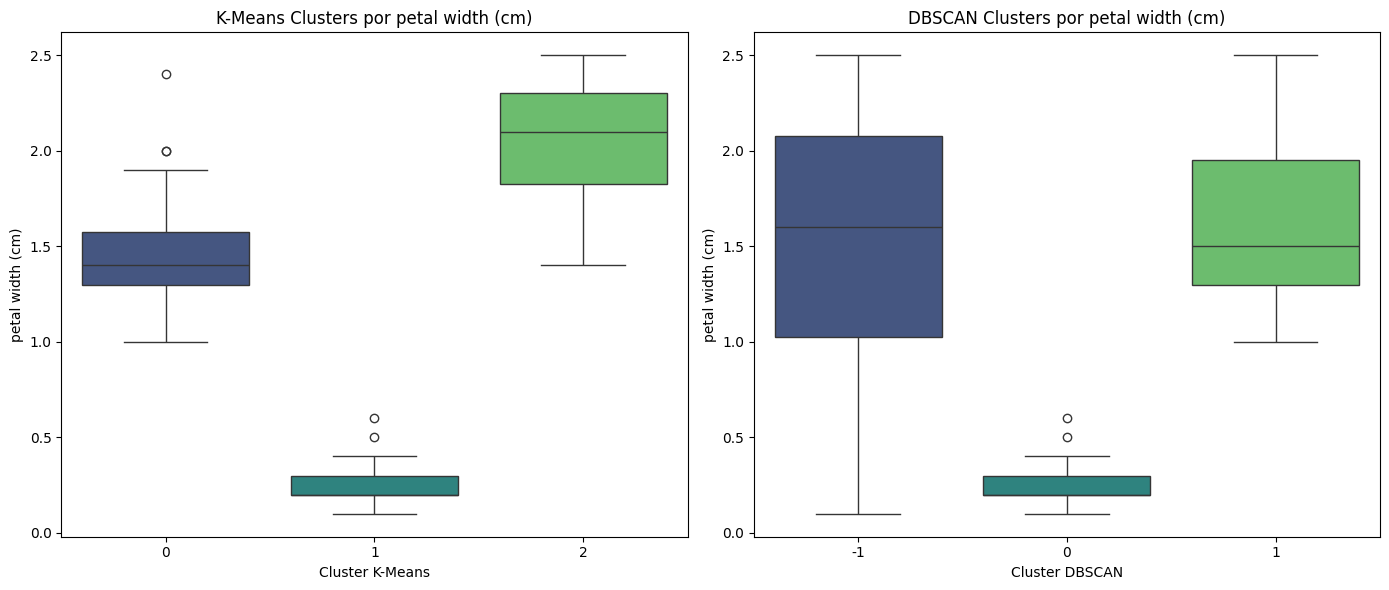

In [12]:
features = iris.feature_names

print("=== Gráficos de Caixa por Cluster (K-Means vs DBSCAN) ===")

for feature in features:
    plt.figure(figsize=(14, 6))

    # Box plot para K-Means
    plt.subplot(1, 2, 1)
    sns.boxplot(x='kmeans_labels', y=feature, data=df, palette='viridis')
    plt.title(f'K-Means Clusters por {feature}')
    plt.xlabel('Cluster K-Means')
    plt.ylabel(feature)

    # Box plot para DBSCAN
    plt.subplot(1, 2, 2)
    sns.boxplot(x='dbscan_labels', y=feature, data=df, palette='viridis')
    plt.title(f'DBSCAN Clusters por {feature}')
    plt.xlabel('Cluster DBSCAN')
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()
